# Phase 1.2 — Exploratory Data Analysis

Inputs: `data/master.csv` (from `build_master.py`) and `results/splits.csv` (frozen).
Outputs: figures in `results/figures/`, tables in `results/tables/`.

Region groups: **hand**, **leg**, **hip** (= hip + leg+hip), **shoulder** (= shoulder + hand+shoulder), **other** (24 odd combinations, unified model only).

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile, ImageOps
import sys

# A few FracAtlas files are partially corrupt; load whatever pixels are readable.
# (src/check_images.py lists the affected files.)
ImageFile.LOAD_TRUNCATED_IMAGES = True

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

ORDER = ["hand", "leg", "hip", "shoulder", "other"]
REGIONS = ["hand", "leg", "hip", "shoulder"]          # groups that get their own model
PALETTE = dict(zip(ORDER, sns.color_palette("colorblind", 5)))
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42

sys.path.insert(0, str(ROOT / "src"))
from paths import image_path      # master.csv stores paths relative to data/FracAtlas (or $FRACATLAS_DIR)

master = pd.read_csv(ROOT / "data" / "master.csv")
splits = pd.read_csv(ROOT / "results" / "splits.csv")
df = master.merge(splits[["image_id", "split", "fold"]], on="image_id", how="inner", validate="one_to_one")
assert len(df) == len(master) == len(splits), "master and splits do not line up"
print(df.shape)
df.head(3)

(4083, 21)


,image_id,hand,leg,hip,shoulder,fractured,mixed,hardware,multiscan,fracture_count,...,region_detail,region_group,file_path,in_both_folders,n_boxes,boxes_xywh,width,height,split,fold
0,IMG0000000.jpg,0,1,0,0,0,0,0,1,0,...,leg,leg,C:\University\Semester 5\Machine Learning\Proj...,0,0,[],1760,2140,train,3
1,IMG0000001.jpg,0,1,0,0,0,0,0,1,0,...,leg,leg,C:\University\Semester 5\Machine Learning\Proj...,0,0,[],1760,2140,test,-1
2,IMG0000002.jpg,0,1,0,0,0,0,0,1,0,...,leg,leg,C:\University\Semester 5\Machine Learning\Proj...,0,0,[],1760,2140,train,2


## 1. Counts and fracture rate

In [ ]:
counts = pd.crosstab(df["region_group"], df["fractured"]).reindex(ORDER)
counts.columns = ["normal", "fractured"]
counts["total"] = counts.sum(axis=1)
counts["fracture_rate_%"] = (100 * counts["fractured"] / counts["total"]).round(1)
counts.loc["ALL"] = [counts["normal"].sum(), counts["fractured"].sum(), counts["total"].sum(),
                     round(100 * counts["fractured"].sum() / counts["total"].sum(), 1)]
counts.to_csv(TAB / "eda_counts_region_group.csv")
counts

,normal,fractured,total,fracture_rate_%
region_group,,,,
hand,900.0,381.0,1281.0,29.7
leg,1912.0,212.0,2124.0,10.0
hip,263.0,57.0,320.0,17.8
shoulder,274.0,60.0,334.0,18.0
other,15.0,9.0,24.0,37.5
ALL,3364.0,719.0,4083.0,17.6


In [ ]:
detail = pd.crosstab(df["region_detail"], df["fractured"])
detail.columns = ["normal", "fractured"]
detail["total"] = detail.sum(axis=1)
detail["fracture_rate_%"] = (100 * detail["fractured"] / detail["total"]).round(1)
detail = detail.join(df.groupby("region_detail")["region_group"].first())
detail = detail.sort_values(["region_group", "total"], ascending=[True, False])
detail.to_csv(TAB / "eda_counts_region_detail.csv")
detail

,normal,fractured,total,fracture_rate_%,region_group
region_detail,,,,,
hand,900,381,1281,29.7,hand
hip,169,10,179,5.6,hip
leg+hip,94,47,141,33.3,hip
leg,1912,212,2124,10.0,leg
hand+hip+shoulder,11,3,14,21.4,other
hand+leg,3,3,6,50.0,other
hand+hip,0,2,2,100.0,other
hand+leg+hip,0,1,1,100.0,other
hand+leg+hip+shoulder,1,0,1,0.0,other


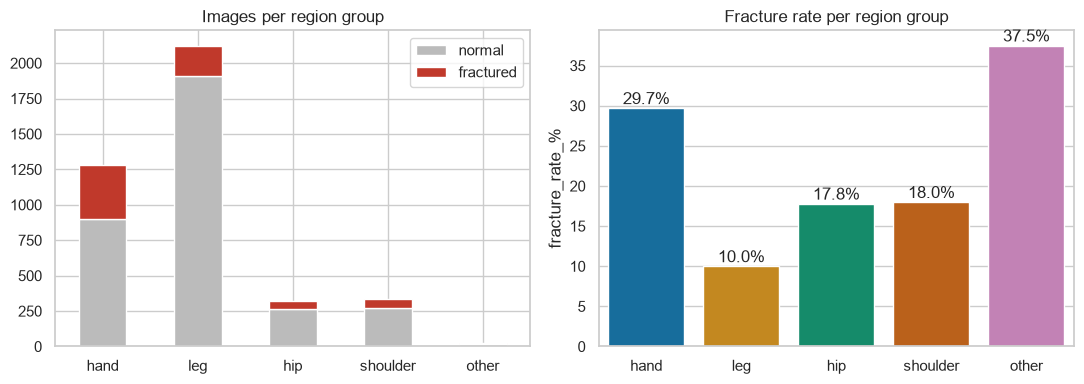

In [ ]:
g = counts.drop("ALL").reset_index()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
g.set_index("region_group")[["normal", "fractured"]].plot.bar(stacked=True, ax=ax[0], color=["#bbbbbb", "#c0392b"], rot=0)
ax[0].set_title("Images per region group"); ax[0].set_xlabel("")
sns.barplot(data=g, x="region_group", y="fracture_rate_%", ax=ax[1], palette=PALETTE, hue="region_group", legend=False, order=ORDER)
for i, r in enumerate(g["fracture_rate_%"]):
    ax[1].text(i, r + 0.5, f"{r}%", ha="center")
ax[1].set_title("Fracture rate per region group"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "eda_counts_rates.png", dpi=150); plt.show()

## 2. Hardware (implants) and the shortcut risk
97 of the 99 hardware images are fractured. A classifier could learn "implant → fracture". Check how much of each region's fracture count this is.

In [ ]:
hw = pd.crosstab([df["region_group"], df["hardware"]], df["fractured"]).reindex(ORDER, level=0)
hw.columns = ["normal", "fractured"]
hw.to_csv(TAB / "eda_hardware.csv")
share = (df[df.fractured == 1].groupby("region_group")["hardware"].mean() * 100).round(1).reindex(ORDER)
print("% of fractured images that contain hardware, per region group:")
print(share.to_string())
hw

% of fractured images that contain hardware, per region group:
region_group
hand         5.5
leg         24.5
hip         35.1
shoulder     5.0
other       11.1


normal  fractured
region_group hardware                   
hand         0            900        360
             1              0         21
leg          0           1910        160
             1              2         52
hip          0            263         37
             1              0         20
shoulder     0            274         57
             1              0          3
other        0             15          8
             1              0          1

## 3. Frozen split check (every region needs fractured images in train and test)

In [ ]:
chk = df.groupby(["split", "region_group", "fractured"]).size().unstack("fractured", fill_value=0)
chk.columns = ["normal", "fractured"]
chk.to_csv(TAB / "eda_split_check.csv")
chk

normal  fractured
split region_group                   
test  hand             180         76
      hip               53         11
      leg              383         42
      other              3          2
      shoulder          55         12
train hand             720        305
      hip              210         46
      leg             1529        170
      other             12          7
      shoulder         219         48

## 4. Image sizes and aspect ratios

In [ ]:
df["aspect"] = df["width"] / df["height"]
df["megapixels"] = df["width"] * df["height"] / 1e6
size_tab = df.groupby("region_group")[["width", "height", "aspect"]].describe().loc[ORDER]
size_tab.to_csv(TAB / "eda_image_sizes.csv")
print("Distinct image sizes:", df.groupby(["width", "height"]).ngroups)
print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head(8).to_string())

Distinct image sizes: 11
width  height
373    454       2703
454    373       1024
2304   2880       303
1760   2140        24
2880   2304        23
181    454          1
296    454          1
373    214          1


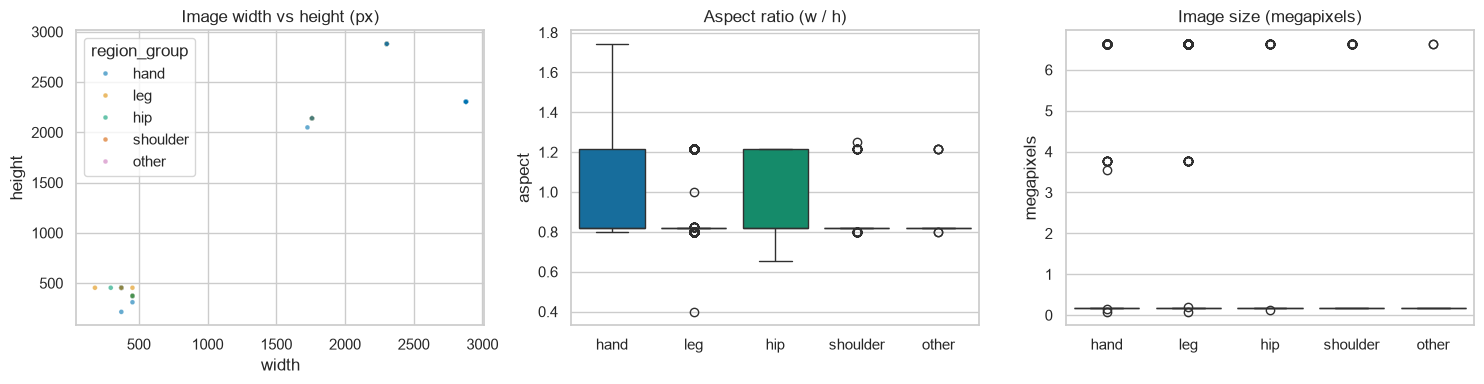

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.scatterplot(data=df, x="width", y="height", hue="region_group", hue_order=ORDER, palette=PALETTE, s=12, alpha=.6, ax=ax[0])
ax[0].set_title("Image width vs height (px)")
sns.boxplot(data=df, x="region_group", y="aspect", order=ORDER, palette=PALETTE, hue="region_group", legend=False, ax=ax[1])
ax[1].set_title("Aspect ratio (w / h)"); ax[1].set_xlabel("")
sns.boxplot(data=df, x="region_group", y="megapixels", order=ORDER, palette=PALETTE, hue="region_group", legend=False, ax=ax[2])
ax[2].set_title("Image size (megapixels)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "eda_image_sizes.png", dpi=150); plt.show()

## 5. Bounding-box statistics
These decide the patch sizes in Phase 7. Percentiles use **training images only**, and sizes are expressed in the 256x256 space used after "pad to square, resize" (scale = 256 / max(width, height)).

In [ ]:
rows = []
for _, r in df[df["n_boxes"] > 0].iterrows():
    for x, y, w, h in json.loads(r["boxes_xywh"]):
        scale = 256 / max(r["width"], r["height"])
        rows.append(dict(image_id=r["image_id"], region_group=r["region_group"], split=r["split"],
                         x=x, y=y, w=w, h=h,
                         area_frac=(w * h) / (r["width"] * r["height"]),
                         side_px=np.sqrt(w * h),
                         side_256=np.sqrt(w * h) * scale,
                         w_256=w * scale, h_256=h * scale))
boxes = pd.DataFrame(rows)
print(len(boxes), "boxes in", boxes["image_id"].nunique(), "images")

924 boxes in 719 images


In [ ]:
q = lambda p: (lambda s: s.quantile(p))
bs = boxes.groupby("region_group").agg(
    n_boxes=("w", "size"),
    median_w=("w", "median"), median_h=("h", "median"),
    area_frac_p25=("area_frac", q(.25)), area_frac_med=("area_frac", "median"), area_frac_p75=("area_frac", q(.75)),
).reindex([g for g in ORDER if g in boxes.region_group.unique()]).round(4)
bs.to_csv(TAB / "eda_box_stats_by_region.csv")
bs

,n_boxes,median_w,median_h,area_frac_p25,area_frac_med,area_frac_p75
region_group,,,,,,
hand,484,25.80,23.90,0.0020,0.0032,0.0052
leg,303,26.50,41.80,0.0031,0.0052,0.0098
hip,60,45.35,70.70,0.0073,0.0183,0.0289
shoulder,64,42.55,42.45,0.0024,0.0042,0.0066
other,13,28.70,26.50,0.0017,0.0022,0.0030


In [ ]:
tr = boxes[boxes["split"] == "train"]
pct = pd.DataFrame({
    "all regions": tr["side_256"].quantile([.25, .5, .75]),
    **{r: tr[tr.region_group == r]["side_256"].quantile([.25, .5, .75]) for r in REGIONS if (tr.region_group == r).any()},
}).round(1)
pct.index = ["p25", "p50", "p75"]
pct.to_csv(TAB / "eda_box_side_percentiles_256.csv")
print("Box side length (sqrt(w*h)) in the 256x256 space, TRAIN boxes only:")
pct

Box side length (sqrt(w*h)) in the 256x256 space, TRAIN boxes only:


,all regions,hand,leg,hip,shoulder
p25,11.3,10.6,12.9,19.9,11.1
p50,14.7,13.3,16.7,30.8,15.3
p75,20.1,16.9,23.8,37.4,18.9


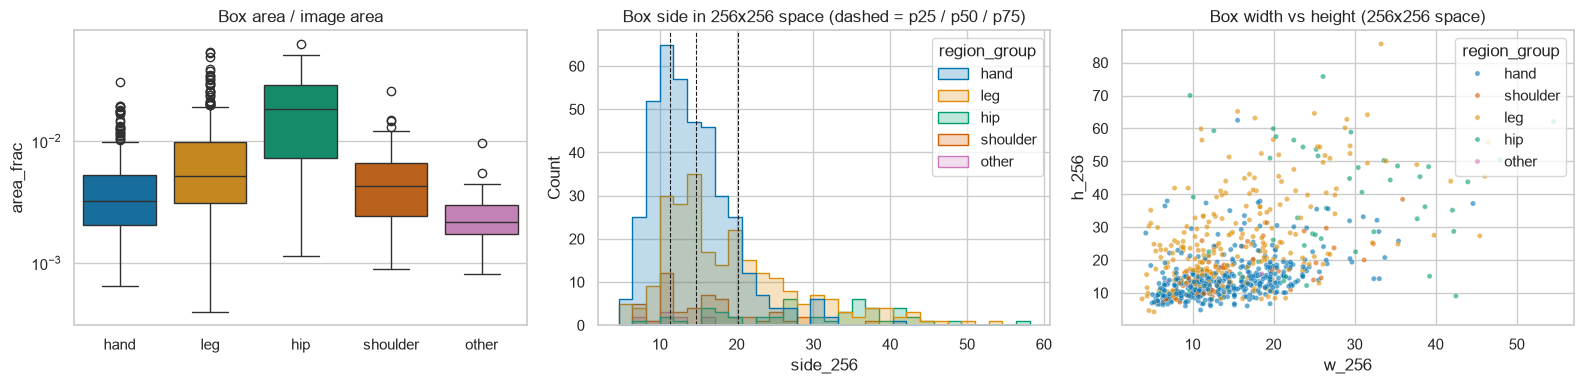

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=boxes, x="region_group", y="area_frac", order=[g for g in ORDER if g in boxes.region_group.unique()], palette=PALETTE, hue="region_group", legend=False, ax=ax[0])
ax[0].set_yscale("log"); ax[0].set_title("Box area / image area"); ax[0].set_xlabel("")
sns.histplot(data=tr, x="side_256", hue="region_group", hue_order=[g for g in ORDER if g in tr.region_group.unique()],
             palette=PALETTE, bins=30, element="step", ax=ax[1])
for p in tr["side_256"].quantile([.25, .5, .75]):
    ax[1].axvline(p, color="k", ls="--", lw=.8)
ax[1].set_title("Box side in 256x256 space (dashed = p25 / p50 / p75)")
sns.scatterplot(data=tr, x="w_256", y="h_256", hue="region_group", palette=PALETTE, s=14, alpha=.6, ax=ax[2])
ax[2].set_title("Box width vs height (256x256 space)")
plt.tight_layout(); plt.savefig(FIG / "eda_box_stats.png", dpi=150); plt.show()

In [ ]:
mult = df[df.fractured == 1].groupby("region_group")["n_boxes"].value_counts().unstack(fill_value=0).reindex(ORDER)
mult.to_csv(TAB / "eda_boxes_per_image.csv")
print("Fractured images by number of boxes:")
mult

Fractured images by number of boxes:


n_boxes,1,2,3,4,5
region_group,,,,,
hand,290,83,4,4,0
leg,143,52,13,3,1
hip,54,3,0,0,0
shoulder,56,4,0,0,0
other,5,4,0,0,0


## 6. Sample grid: fractured (top row) and normal (bottom row), boxes overlaid

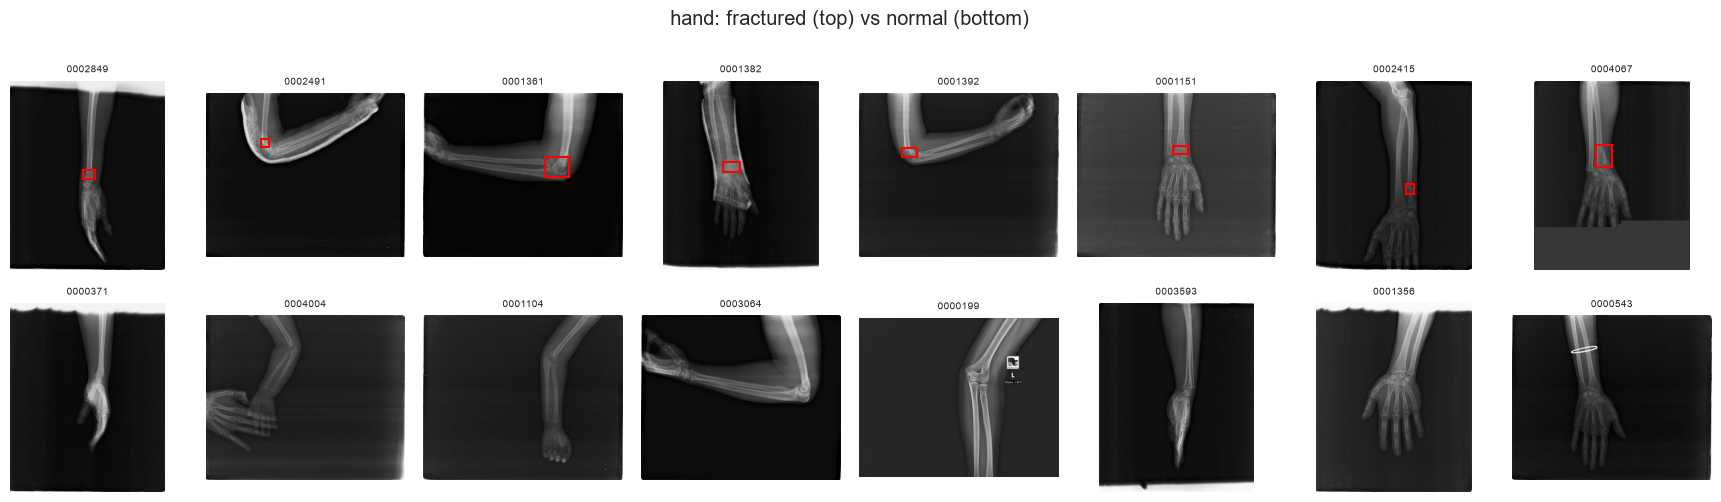

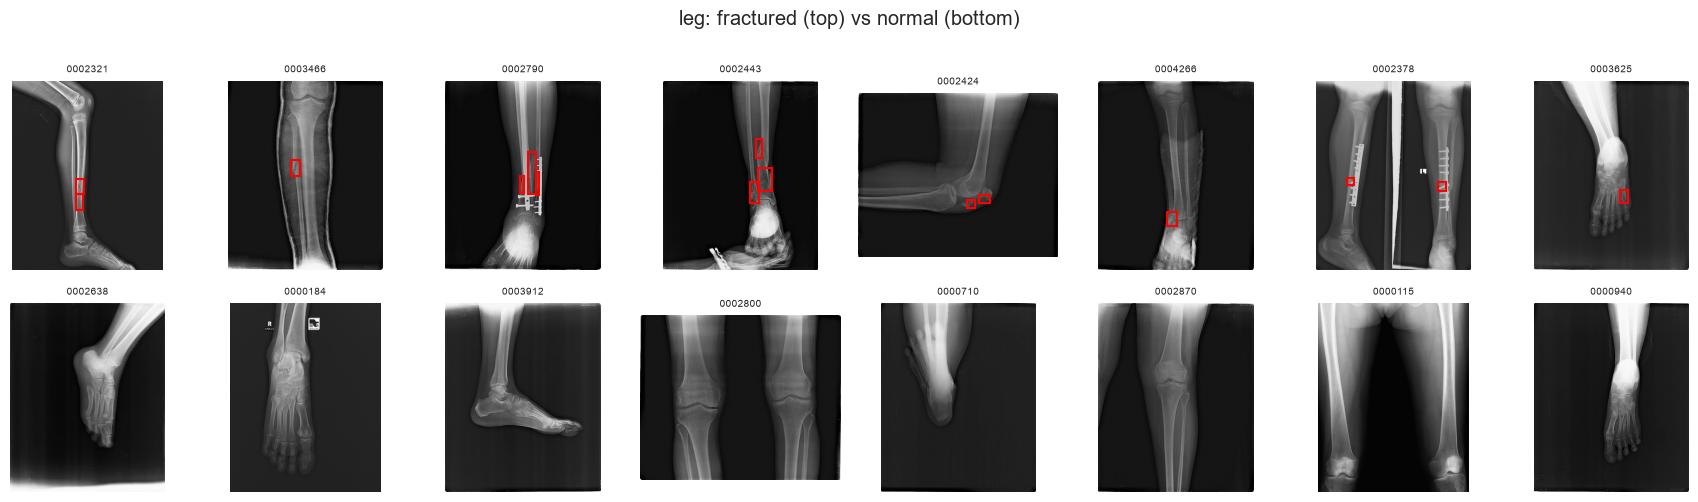

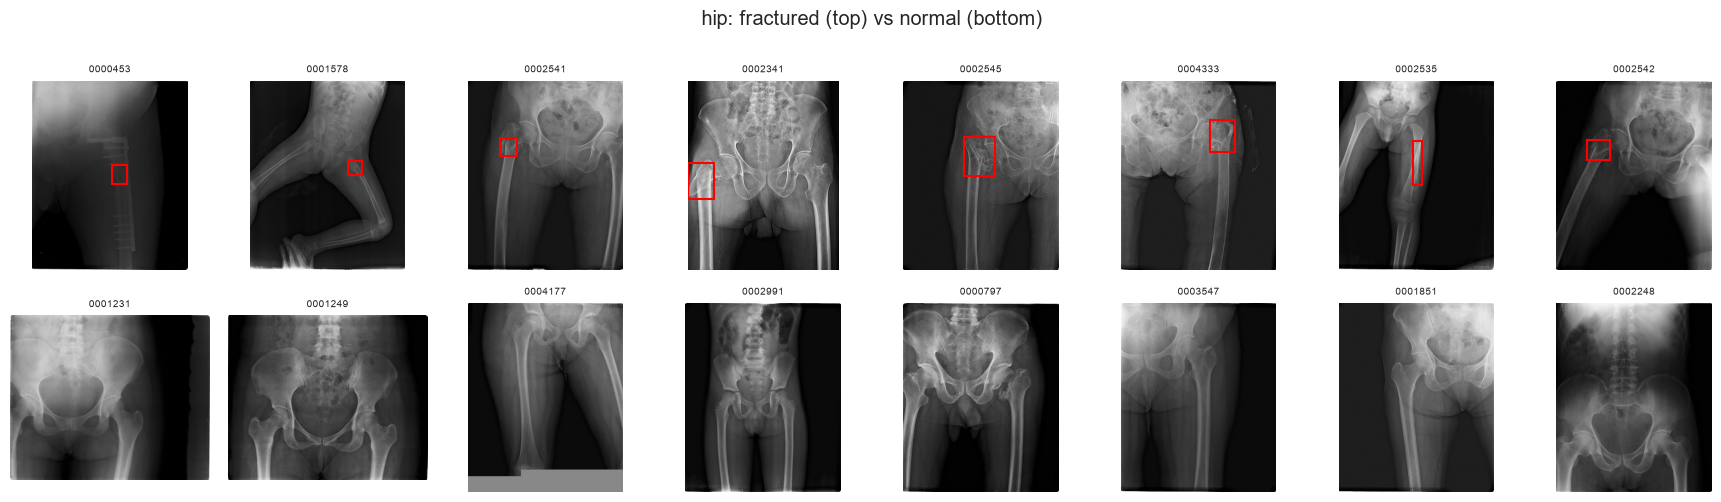

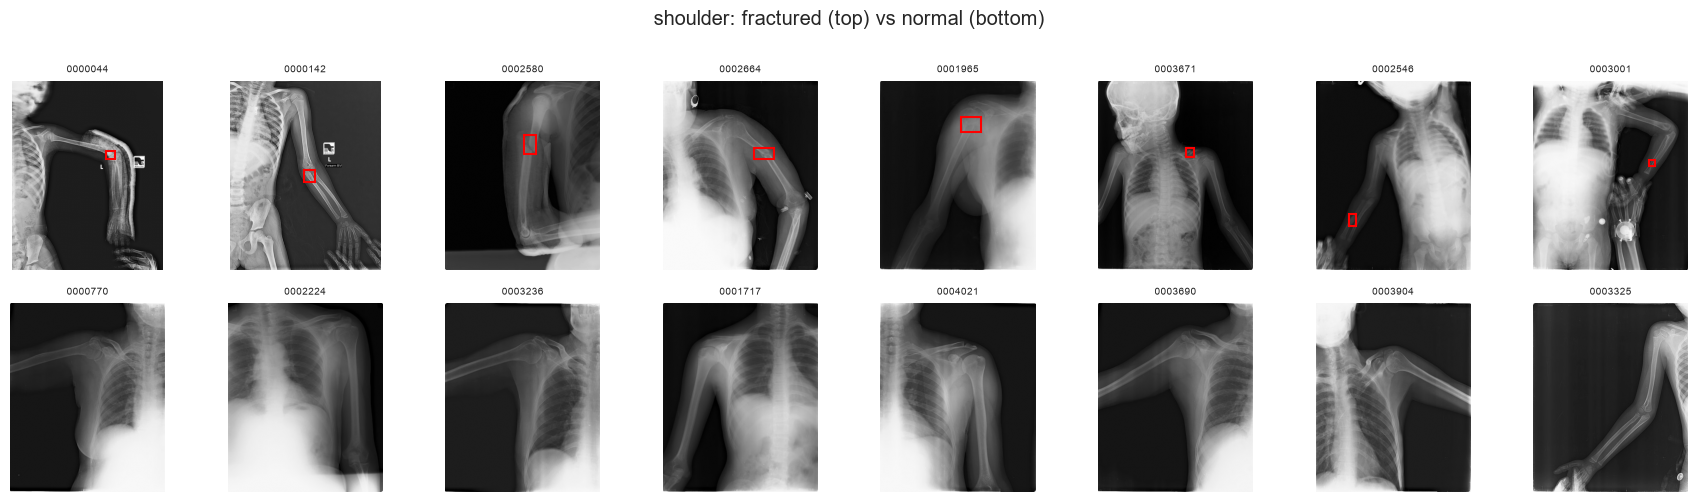

In [ ]:
def load_gray(path):
    with Image.open(image_path(path)) as im:
        # apply the EXIF rotation tag so the pixels match the COCO box coordinates
        return np.asarray(ImageOps.exif_transpose(im).convert("L"))

def sample_grid(region, n=8, seed=SEED):
    sub = df[df["region_group"] == region]
    fr = sub[sub.fractured == 1].sample(min(n, (sub.fractured == 1).sum()), random_state=seed)
    nm = sub[sub.fractured == 0].sample(min(n, (sub.fractured == 0).sum()), random_state=seed)
    fig, axes = plt.subplots(2, n, figsize=(2.2 * n, 5))
    for row, part in enumerate([fr, nm]):
        for col in range(n):
            ax = axes[row, col]; ax.axis("off")
            if col >= len(part):
                continue
            r = part.iloc[col]
            ax.imshow(load_gray(r["file_path"]), cmap="gray")
            for x, y, w, h in json.loads(r["boxes_xywh"]):
                ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="red", lw=1.5))
            ax.set_title(r["image_id"][3:-4], fontsize=7)
    fig.suptitle(f"{region}: fractured (top) vs normal (bottom)", y=1.0)
    plt.tight_layout(); plt.savefig(FIG / f"eda_samples_{region}.png", dpi=120); plt.show()

for r in REGIONS:
    sample_grid(r)

### Does the merge hold up?
Hip = hip + leg+hip, shoulder = shoulder + hand+shoulder. Look at the original-label images side by side: if `leg+hip` images look like hip views (with some leg in frame) and `hand+shoulder` like shoulder views, the grouping is sensible.

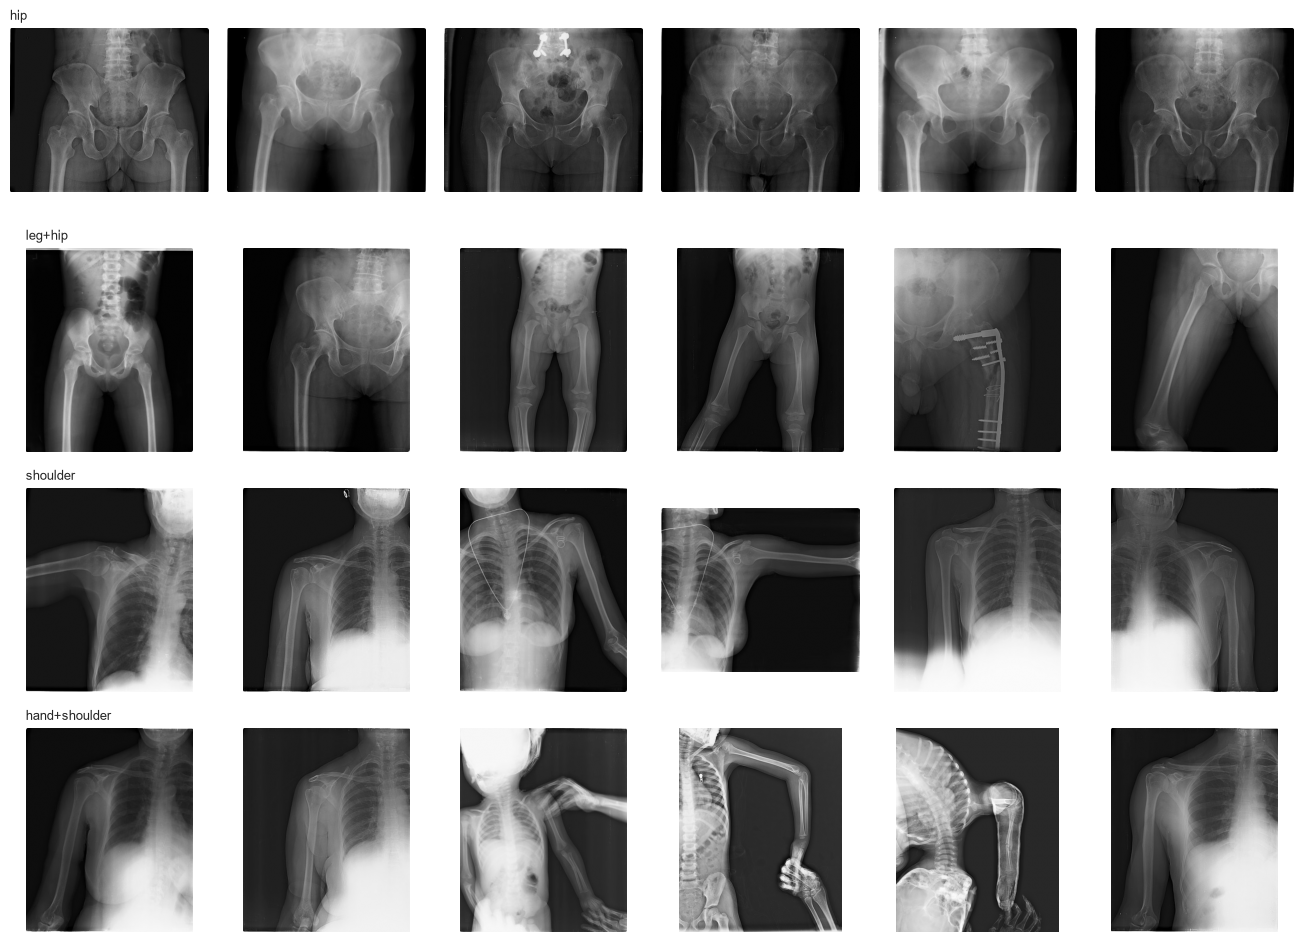

In [ ]:
def detail_grid(detail_names, n=6, seed=SEED):
    fig, axes = plt.subplots(len(detail_names), n, figsize=(2.2 * n, 2.4 * len(detail_names)))
    axes = np.atleast_2d(axes)
    for i, name in enumerate(detail_names):
        sub = df[df["region_detail"] == name].sample(n, random_state=seed)
        for j in range(n):
            ax = axes[i, j]; ax.axis("off")
            ax.imshow(load_gray(sub.iloc[j]["file_path"]), cmap="gray")
            if j == 0:
                ax.set_title(name, fontsize=9, loc="left")
    plt.tight_layout(); plt.savefig(FIG / "eda_merge_check.png", dpi=120); plt.show()

detail_grid(["hip", "leg+hip", "shoulder", "hand+shoulder"])

## 7. Intensity histograms (exposure / contrast differences)

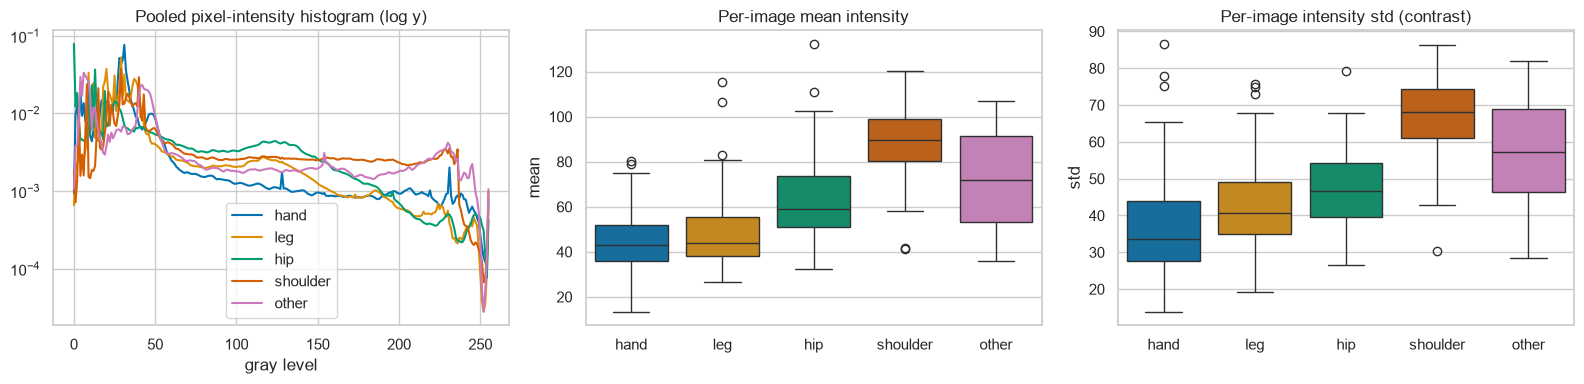

In [ ]:
rng = np.random.default_rng(SEED)
N = 150                                    # images sampled per region group
hist, stats = {}, []
for g in ORDER:
    sub = df[df["region_group"] == g]
    sub = sub.iloc[rng.permutation(len(sub))[:N]]
    acc = np.zeros(256)
    for _, r in sub.iterrows():
        a = load_gray(r["file_path"])
        acc += np.bincount(a.ravel(), minlength=256)
        stats.append(dict(region_group=g, mean=a.mean(), std=a.std()))
    hist[g] = acc / acc.sum()
stats = pd.DataFrame(stats)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for g in ORDER:
    ax[0].plot(hist[g], label=g, color=PALETTE[g])
ax[0].set_yscale("log"); ax[0].set_title("Pooled pixel-intensity histogram (log y)"); ax[0].set_xlabel("gray level"); ax[0].legend()
sns.boxplot(data=stats, x="region_group", y="mean", order=ORDER, palette=PALETTE, hue="region_group", legend=False, ax=ax[1]); ax[1].set_title("Per-image mean intensity"); ax[1].set_xlabel("")
sns.boxplot(data=stats, x="region_group", y="std", order=ORDER, palette=PALETTE, hue="region_group", legend=False, ax=ax[2]); ax[2].set_title("Per-image intensity std (contrast)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "eda_intensity.png", dpi=150); plt.show()
stats.groupby("region_group")[["mean", "std"]].describe().round(1).reindex(ORDER).to_csv(TAB / "eda_intensity_stats.csv")

## 8. Findings

- **Counts:** 4,083 images, 719 fractured (17.6%). The plan said 717; the `Fractured` folder, `dataset.csv` and the COCO boxes all agree on 719.
- **Region grouping:** hip and shoulder have only 10 fractured single-region images each, so `leg+hip` -> hip and `hand+shoulder` -> shoulder. The 24 odd combinations -> `other` (unified model only). Fracture rates: hand 29.7%, leg 10.0%, hip 17.8%, shoulder 18.0%.
- **Does the merge hold up visually?** Yes. leg+hip images are pelvis/femur views and hand+shoulder images are chest/shoulder views with the arm in frame, so they show the same anatomy as hip and shoulder. Caveat: hip sub-groups differ (hip alone 6% fractured vs leg+hip 33%; leg+hip includes paediatric and femur-only images), so report hip results by `region_detail` in the error analysis.
- **Hardware:** 99 images, 97 of them fractured (20 fractured hardware images in test, 77 in train). Treat as a shortcut risk: report results with and without, and check in the error analysis.
- **Image integrity:** 59 truncated JPEGs (all normal images, each missing 0-67 bytes at the end): kept, loaded with `LOAD_TRUNCATED_IMAGES = True`. One image (IMG0002628) carries EXIF orientation 8, so Pillow shows it sideways relative to its COCO box; verified that the box is correct after `ImageOps.exif_transpose`. All loaders apply it.
- **Image sizes:** 11 distinct sizes. 91% of images are 373x454 (2,703) or 454x373 (1,024). About 350 are high resolution (2304x2880: 303, 2880x2304: 23, 1760x2140: 24; ~6 MP vs 0.17 MP), plus 6 odd crops. Aspect ratios are all about 0.8 or 1.25, so square padding adds about 20% border. Resizing to 256 shrinks the small images 1.8x but the large ones 8-11x. Native size for most images is ~454 px, so test 256 vs ~448 in Phase 2 (512 would only upsample).
- **Resolution shortcut:** the 351 high-resolution images are spread evenly across regions (6.6-9.6% of each) but are fractured more often (29.1% vs 16.5%). In the frozen split, test has 28 fractured big images out of 79 (35.4%) vs 74 of 272 in train (27.2%), mildly enriched. Plan: match scale before resizing in Phase 2 (resize everything to ~448 long side with area interpolation first), and report test metrics on all images and on the small-images-only subset (738 images, 115 fractured).
- **Box sizes / patch sizes for Phase 7:** boxes are tiny. Side length in the 256x256 space (train boxes), p25 / p50 / p75: all 11.3 / 14.7 / 20.1; hand 10.6 / 13.3 / 16.9; leg 12.9 / 16.7 / 23.8; hip 19.9 / 30.8 / 37.4; shoulder 11.1 / 15.3 / 18.9. The median box covers about 0.2-0.5% of the image (hip about 1.8%). At 256x256 this is smaller than a 16x16 HOG cell, so Phase 7 needs a higher working resolution and hip needs larger patches than hand.
- **Intensity differences across regions:** large. Median per-image mean intensity: hand 43, leg 44, hip 59, other 72, shoulder 90. Median contrast (std): hand 34, leg 41, hip 47, other 57, shoulder 68. The spread within each region is also wide. CLAHE is needed; also test a per-image z-score. Global intensity features act as region identifiers, and fracture rates differ by region, so compare results with and without the intensity-statistics feature family.